# EDA analysis

**Author** : Vukasin Jovanovic

**Date** : 23.11.2026

## Objective

The goal of this project is to build a regression model that predicts the price of a used car based on its characteristics (e.g., brand, model, year, mileage, engine, fuel type).

This notebook covers the **Exploratory Data Analysis (EDA)** phase. Its purpose is to:

- Understand the structure and content of the dataset
- Assess data quality (missing values, duplicates, invalid or inconsistent entries)
- Analyze the distribution of the target variable (`price`)
- Identify the features most strongly related to price
- Detect outliers, skewness and multicollinearity that may affect modeling

The findings from this analysis will guide the next steps: **data cleaning**, **feature engineering** and **model selection**.

## Setup

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None) # show all columns in head()
pd.set_option("display.float_format", "{:,.2f}".format) # readable numbers in describe()

sns.set_theme(style="whitegrid", palette="deep")  # consistent style for all plots
plt.rcParams["figure.figsize"] = (10, 6) # default plot size

In [2]:
df = pd.read_csv('../data/raw/cars.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  str    
 1   model                56244 non-null  str    
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  str    
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  str    
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  str    
 9   transmission         56244 non-null  str    
 10  drive_unit           54339 non-null  str    
 11  segment              50953 non-null  str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.1 MB


### Observations
- The dataset has 56,244 rows and 12 columns: 4 numerical and 8 categorical.
- The target variable `priceUSD` has no missing values.
- Three columns have missing values:
    - `volume(cm3)`: 47 (0.08%)
    - `drive_unit`: 1,905 (3.4%)
    - `segment`: 5,291 (9.4%)

    The first two are small enough for simple imputation or row removal. `segment` needs a closer look during data cleaning.

- Column names mix camelCase and units in parentheses, so I'll rename them to snake_case.
- `mileage(kilometers)` is stored as `float`, even though mileage should be a whole number. Next I'll check whether any values have a fractional part.

In [3]:
df.columns = [x.lower().replace('(', '_').replace(')',' ').strip().replace(' ','_') for x in df.columns]
df = df.rename(columns={"priceusd" : "price_usd"})

In [4]:
display(df.head())

df.describe().T

,make,model,price_usd,year,condition,mileage_kilometers,fuel_type,volume_cm3,color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,"162,000.00",petrol,"1,500.00",burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,"120,000.00",petrol,"1,300.00",black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,"61,000.00",petrol,"1,500.00",silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,"265,000.00",diesel,"1,400.00",white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,"97,183.00",diesel,"1,400.00",gray,mechanics,front-wheel drive,B


,count,mean,std,min,25%,50%,75%,max
price_usd,"56,244.00","7,415.46","8,316.96",48.00,"2,350.00","5,350.00","9,807.50","235,235.00"
year,"56,244.00","2,003.45",8.14,"1,910.00","1,998.00","2,004.00","2,010.00","2,019.00"
mileage_kilometers,"56,244.00","244,395.63","321,030.67",0.00,"137,000.00","228,500.00","310,000.00","9,999,999.00"
volume_cm3,"56,197.00","2,104.86",959.20,500.00,"1,600.00","1,996.00","2,300.00","20,000.00"


### Observations

- `price_usd` ranges from 48 to 235,235 USD. A price of 48 USD is unrealistically low for a car, so I'll look at the cheapest listings. The maximum may be a typo (repeating digits) or a genuine luxury car. The mean (7,415) is well above the median (5,350), so the distribution is right-skewed, and a log transformation of the target may help later.
- `year` has a minimum of 1910. This could be a vintage car or an entry error, and I'll inspect the oldest listings.
- `mileage_kilometers` ranges from 0 to 9,999,999 km. The maximum is almost certainly a placeholder value, and it also inflates the mean (244,396 km). Zero mileage is plausible only for new cars, so I'll compare it with the `condition` column. The column is stored as `float`, although the values in the first rows are whole numbers. I'll check whether any fractional values exist.
- `volume_cm3` has a maximum of 20,000 cm³, which is not realistic for a passenger car and is likely an entry error. I'll look at the largest values before deciding how to handle them.

## Categorical Features

In [5]:
df.describe(include='str').T

,count,unique,top,freq
make,56244,96,volkswagen,6861
model,56244,1034,passat,2086
condition,56244,3,with mileage,55278
fuel_type,56244,3,petrol,36405
color,56244,13,black,12385
transmission,56244,2,mechanics,36056
drive_unit,54339,4,front-wheel drive,38016
segment,50953,9,D,12605


In [6]:
categorical_features = df.select_dtypes(include='str').columns

for c in categorical_features:
    display(df[c].value_counts(normalize=True, dropna=False).head(15))
    print()

make
volkswagen      0.12
audi            0.07
bmw             0.07
opel            0.07
renault         0.07
mercedes-benz   0.06
ford            0.05
peugeot         0.05
nissan          0.04
toyota          0.04
mazda           0.04
citroen         0.04
hyundai         0.03
mitsubishi      0.02
volvo           0.02
Name: proportion, dtype: float64

model
passat        0.04
5-seriya      0.03
a6            0.02
golf          0.02
astra         0.02
e-klass       0.02
3-seriya      0.01
vectra        0.01
laguna        0.01
mondeo        0.01
a4            0.01
scenic        0.01
zafira        0.01
100           0.01
transporter   0.01
Name: proportion, dtype: float64

condition
with mileage   0.98
with damage    0.01
for parts      0.01
Name: proportion, dtype: float64

fuel_type
petrol       0.65
diesel       0.35
electrocar   0.00
Name: proportion, dtype: float64

color
black      0.22
silver     0.18
blue       0.14
gray       0.10
white      0.09
green      0.07
other      0.06
red        0.05
burgundy   0.04
brown      0.02
purple     0.01
yellow     0.01
orange     0.00
Name: proportion, dtype: float64

transmission
mechanics   0.64
auto        0.36
Name: proportion, dtype: float64

drive_unit
front-wheel drive            0.68
rear drive                   0.12
all-wheel drive              0.10
part-time four-wheel drive   0.06
NaN                          0.03
Name: proportion, dtype: float64

segment
D     0.22
C     0.19
J     0.15
M     0.11
E     0.11
NaN   0.09
B     0.08
F     0.02
S     0.01
A     0.01
Name: proportion, dtype: float64

In [7]:
df['fuel_type'].value_counts()

fuel_type
petrol        36405
diesel        19792
electrocar       47
Name: count, dtype: int64

In [8]:
df.loc[df["volume_cm3"].isna(), "fuel_type"].value_counts()

fuel_type
electrocar    47
Name: count, dtype: int64

### Observations

- `make` has 96 unique values and `model` has 1,034. One-hot encoding them would add over 1,000 sparse columns, so these two need a different approach, such as target encoding or grouping rare categories.
- The other categorical features have between 2 (`transmission`) and 13 (`color`) categories, which is low enough for one-hot encoding.
- `condition` is highly imbalanced: 98% of listings are `with mileage`, and `with damage` and `for parts` share the remaining 2%. Damaged cars and cars sold for parts probably sell for much less, which I'll check in the bivariate analysis.
- `fuel_type` has exactly 47 `electrocar` listings, the same number as the missing values in `volume_cm3`. Electric cars have no engine displacement, so these values are expected to be missing.
- 64% of cars have a manual `transmission`, and 70% are front-wheel drive (`drive_unit`).
- Model names are transliterated from Russian (e.g., `5-seriya`, `e-klass`), so the listings probably come from a Russian-speaking market.

## Target Feature

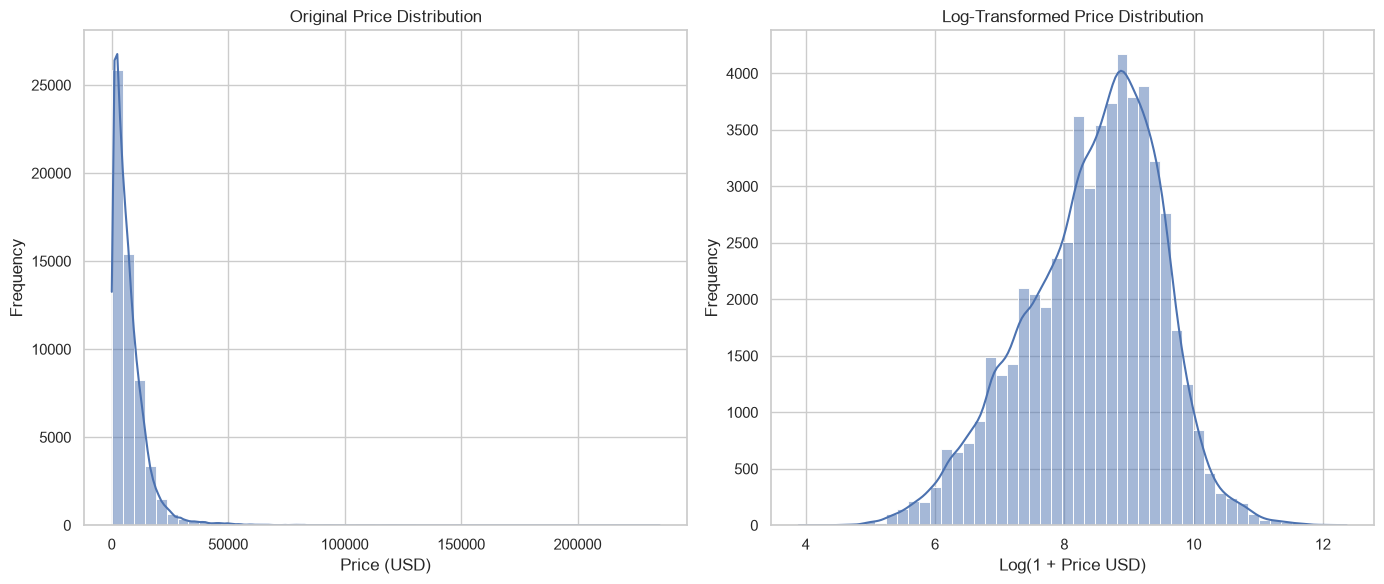

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(x=df['price_usd'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Original Price Distribution')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Frequency')

sns.histplot(x=np.log1p(df['price_usd']), bins=50, kde=True, ax=axes[1])
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('Log(1 + Price USD)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('../reports/figures/price_distribution_original_vs_log.png', dpi=300, bbox_inches='tight')
plt.show()

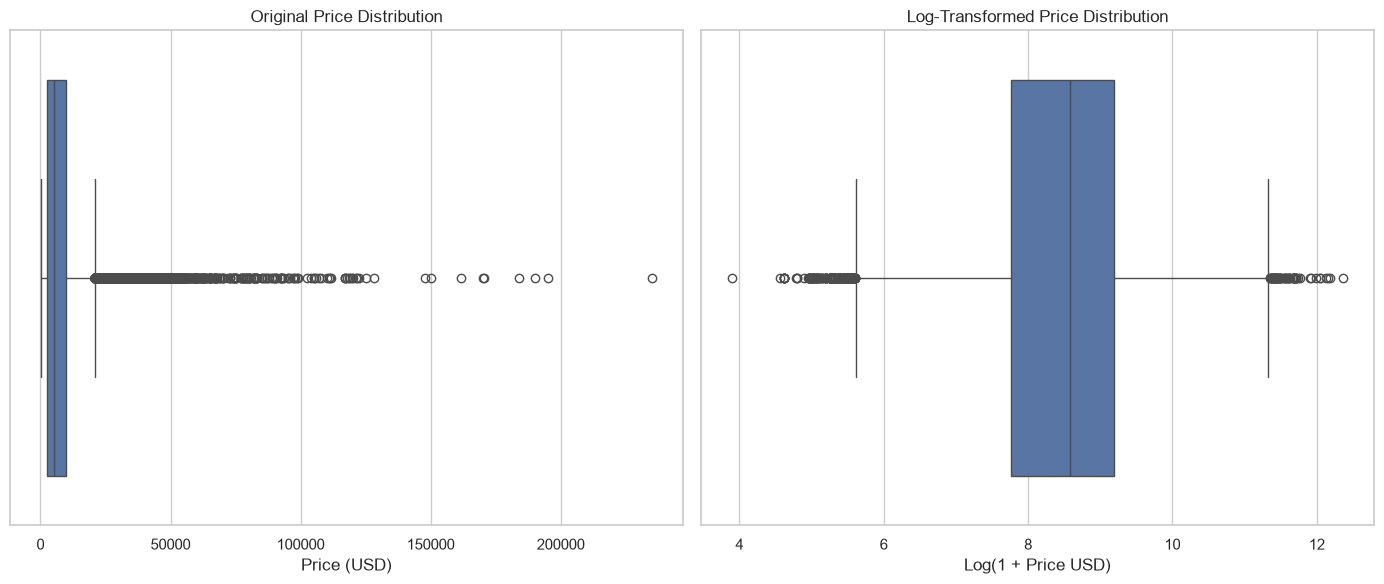

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(x=df['price_usd'], ax=axes[0])
axes[0].set_title('Original Price Distribution')
axes[0].set_xlabel('Price (USD)')

sns.boxplot(x=np.log1p(df['price_usd']), ax=axes[1])
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('Log(1 + Price USD)')

plt.tight_layout()
plt.savefig('../reports/figures/price_boxplots_original_vs_log.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
df["price_usd"].skew()

np.float64(5.142168964138734)

In [12]:
np.log1p(df["price_usd"]).skew()

np.float64(-0.42469979852646994)

In [13]:
df[['make', 'model', 'year', 'condition', 'price_usd']].nsmallest(10, 'price_usd')

,make,model,year,condition,price_usd
5952,zaz,968,1910,with damage,48
40252,proton,persona,1997,with damage,95
5456,mazda,626,1986,with mileage,100
7314,mercedes-benz,190-w201,1991,for parts,100
20971,toyota,corolla,1988,for parts,100
23898,ford,escort,1986,for parts,100
24873,ford,fiesta,1992,for parts,100
41010,nissan,primera,1994,for parts,100
54171,citroen,xantia,1995,for parts,100
7076,lada-vaz,21099,1992,for parts,119


In [14]:
df[['make', 'model', 'year', 'condition', 'price_usd']].nlargest(10, 'price_usd')

,make,model,year,condition,price_usd
20787,bentley,continental-gt,2018,with mileage,235235
16430,bentley,bentayga,2016,with mileage,195000
35457,bentley,mulsanne,2014,with mileage,190141
16428,bentley,bentayga,2016,with mileage,183848
16429,bentley,bentayga,2016,with mileage,170477
19557,porsche,cayenne,2018,with mileage,170000
34508,tesla,model-x,2019,with mileage,161563
26254,mercedes-benz,g-klass,2001,with mileage,150000
33702,mercedes-benz,maybach,2019,with mileage,148000
33327,bmw,m5,2019,with mileage,128136


### Observations

- Raw price is strongly right-skewed (skewness = 5.14). Most cars are cheap, and a small number of very expensive listings pull the mean (7,415 USD) well above the median (5,350 USD).
- After `log1p`, the distribution is close to normal, with a slight left tail (skewness = -0.42), so I'll train the model on log-transformed prices.
- The middle 50% of prices lies between 2,350 and 9,808 USD. On the raw scale, the IQR rule flags thousands of listings as outliers because of the skew, and most of those prices are plausible. On the log scale the boxplot is more balanced, with fewer extreme points on either side. I won't remove outliers based on the raw-scale IQR rule.
- Most of the cheapest listings are `with damage` or `for parts`, so their low prices make sense. The exception is a 1986 Mazda 626 listed `with mileage` for 100 USD, which I'll look at more closely.
- The cheapest listing overall (48 USD) is a ZAZ 968 with `year` = 1910. The 968 was produced from 1971 to 1994, so the year is an entry error. This one row accounts for both the minimum price and the minimum year in `describe()`.
- The most expensive listings are recent luxury cars (Bentley, Porsche, Maybach, Tesla Model X). Their prices look real, so I'll keep them. The exception is a 2001 Mercedes-Benz G-Class at 150,000 USD, which is very high for a car that old and may have the wrong year.

## Numerical Features

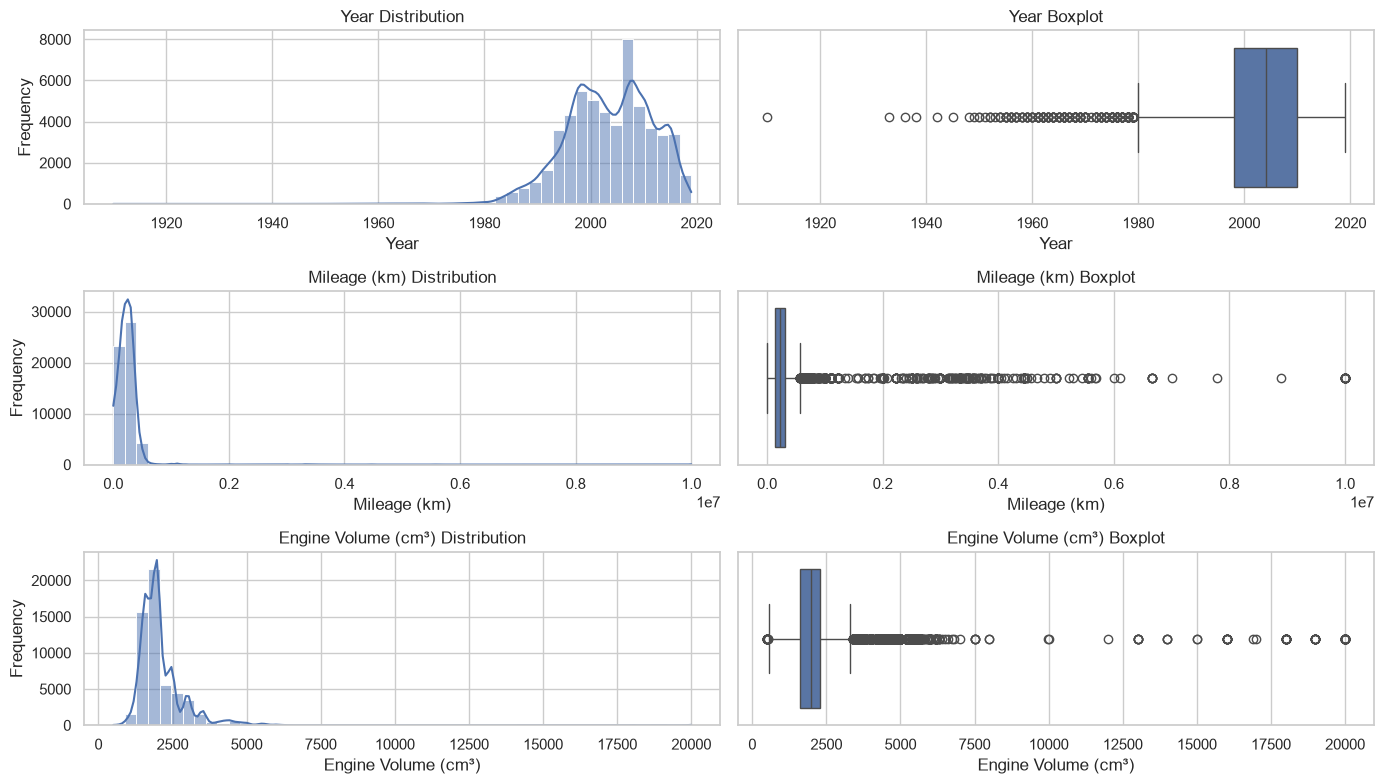

In [15]:
num_cols = ['year', 'mileage_kilometers', 'volume_cm3']

labels = {"year": "Year", "mileage_kilometers": "Mileage (km)", "volume_cm3": "Engine Volume (cm³)"}

fig, axes = plt.subplots(3, 2, figsize=(14, 8))

for i, col in enumerate(num_cols):
    sns.histplot(x=df[col], bins=50, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{labels[col]} Distribution')
    axes[i, 0].set_xlabel(labels[col])
    axes[i, 0].set_ylabel('Frequency')
    
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'{labels[col]} Boxplot')
    axes[i, 1].set_xlabel(labels[col])

plt.tight_layout()
plt.savefig('../reports/figures/numerical_features_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

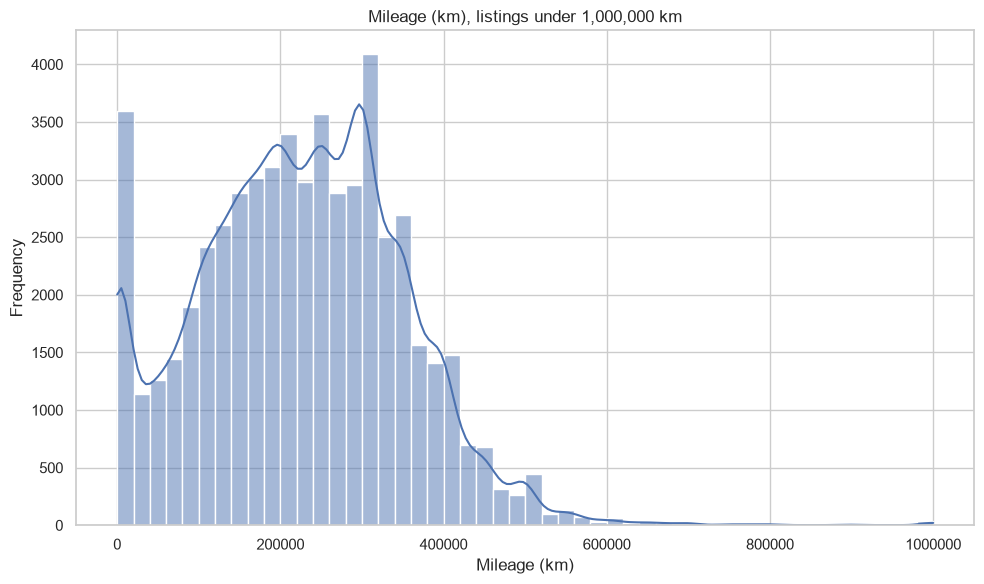

In [16]:
sns.histplot(x=df.loc[(df['mileage_kilometers'] < 1000000), 'mileage_kilometers'], bins=50, kde=True)
plt.title('Mileage (km), listings under 1,000,000 km')
plt.xlabel('Mileage (km)')
plt.ylabel('Frequency')
    
plt.tight_layout()
plt.ticklabel_format(style="plain", axis="x")
plt.savefig('../reports/figures/mileage_distribution_under_1m.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
df[num_cols].skew()

year                 -0.62
mileage_kilometers   17.08
volume_cm3            8.34
dtype: float64

### Observations

- `year` is moderately left-skewed (skewness = -0.62), and most cars were made between about 1998 and 2010. The boxplot flags many cars from 1933 to 1980 as outliers, but most of them look like real vintage cars. The only clear entry error is the ZAZ 968 listed as 1910. The newest cars are from 2019, which suggests the data was collected that year, so I'll use 2019 as the reference year when computing car age.
- `mileage_kilometers` is extremely right-skewed (skewness = 17.08) because of implausible values such as 9,999,999 km. In a separate histogram limited to listings under 1,000,000 km, most cars have between 100,000 and 400,000 km. There is also a spike near zero, which I look at below.
- `volume_cm3` is strongly right-skewed (skewness = 8.34). Most engines are between about 1,600 and 2,300 cm³, and extreme values of up to 20,000 cm³ inflate the skew.
- The next cells look at the suspicious values: entry errors, placeholders, and missing values disguised as numbers. After cleaning, I'll recompute the skewness to see how much of it came from these values.

In [18]:
show_cols = ['make','model','condition','price_usd'] + num_cols

for col in num_cols:
    print(col.capitalize())
    display(df[show_cols].nsmallest(10, col))
    display(df[show_cols].nlargest(10, col))

Year


,make,model,condition,price_usd,year,mileage_kilometers,volume_cm3
5952,zaz,968,with damage,48,1910,"25,000.00","1,100.00"
43024,eksklyuziv,retro,with mileage,50000,1933,1.00,"2,400.00"
43020,eksklyuziv,retro,with damage,4991,1936,"175,000.00","1,800.00"
43025,eksklyuziv,retro,with mileage,12500,1938,"100,000.00","3,000.00"
42986,eksklyuziv,redkaya-model,with mileage,17000,1942,"40,000.00","2,000.00"
52637,eksklyuziv,voennaya-tehnika,with mileage,20000,1945,1.00,"2,199.00"
1048,gaz,67,with mileage,9200,1948,"100,000.00","3,200.00"
33000,gaz,m-20-pobeda,with mileage,2800,1949,"55,555.00","2,400.00"
32995,gaz,m-20-pobeda,with mileage,2000,1950,"100,000.00","2,400.00"
32998,gaz,m-20-pobeda,with mileage,5900,1950,"1,111.00","2,200.00"


,make,model,condition,price_usd,year,mileage_kilometers,volume_cm3
7398,lada-vaz,2121-niva,with mileage,11250,2019,"3,000.00","1,700.00"
7448,lada-vaz,2121-niva,with mileage,12000,2019,"3,000.00","1,700.00"
7910,bmw,3-seriya,with mileage,37900,2019,75.00,"2,000.00"
7923,bmw,3-seriya,with mileage,49800,2019,"22,000.00","2,000.00"
7930,bmw,3-seriya,with mileage,47000,2019,100.00,"2,000.00"
8028,bmw,3-seriya,with mileage,47466,2019,10.00,"1,995.00"
8034,bmw,3-seriya,with mileage,43900,2019,15.00,"2,000.00"
8652,bmw,5-seriya,with mileage,48500,2019,"5,000.00","3,000.00"
8919,bmw,5-seriya,with mileage,63143,2019,15.00,"3,000.00"
9017,bmw,5-seriya,with mileage,38000,2019,0.00,"2,000.00"


Mileage_kilometers


,make,model,condition,price_usd,year,mileage_kilometers,volume_cm3
184,mazda,3,with mileage,5500,2007,0.00,"1,600.00"
809,renault,19,for parts,209,1991,0.00,"1,700.00"
863,gaz,21,with mileage,999,1961,0.00,"2,400.00"
910,renault,21,with mileage,500,1992,0.00,"1,900.00"
1009,uaz,31,with mileage,1300,1994,0.00,"2,400.00"
1059,gaz,69,with mileage,1000,1966,0.00,"2,000.00"
1069,gaz,69,with mileage,4754,1962,0.00,"1,600.00"
1376,audi,80,with mileage,1350,1988,0.00,"1,800.00"
1576,audi,90,with mileage,1100,1989,0.00,"2,400.00"
1836,audi,100,with mileage,2650,1993,0.00,"2,400.00"


,make,model,condition,price_usd,year,mileage_kilometers,volume_cm3
1394,audi,80,with mileage,500,1986,"9,999,999.00","1,800.00"
1854,audi,100,with mileage,900,1989,"9,999,999.00","2,300.00"
5783,peugeot,806,with mileage,4100,2000,"9,999,999.00","2,000.00"
6114,lada-vaz,2104,with mileage,600,1990,"9,999,999.00","1,500.00"
6465,lada-vaz,2108,with mileage,295,1990,"9,999,999.00","1,100.00"
6684,raf,2203,with mileage,1000,1991,"9,999,999.00","2,400.00"
10032,bmw,5-seriya,with mileage,2000,1985,"9,999,999.00","2,800.00"
10316,bmw,7-seriya,with mileage,4650,1998,"9,999,999.00","3,000.00"
11699,audi,a4,with mileage,3000,1996,"9,999,999.00","1,800.00"
16705,fiat,brava,with mileage,1100,1997,"9,999,999.00","1,400.00"


Volume_cm3


,make,model,condition,price_usd,year,mileage_kilometers,volume_cm3
1449,audi,80,with mileage,3327,1993,"437,000.00",500.00
2037,audi,100,with mileage,900,1982,"100,000.00",500.00
5281,mazda,626,with mileage,1000,1993,"100,000.00",500.00
5976,luaz,969,with mileage,500,1982,"2,222,222.00",500.00
6077,lada-vaz,2102,with mileage,650,1976,"67,000.00",500.00
6264,lada-vaz,2106,with mileage,309,1989,"5,000.00",500.00
18927,volkswagen,caravelle,with mileage,3900,1994,"11,111.00",500.00
23974,ford,escort,with mileage,700,1992,"1,111,111.00",500.00
24981,ford,fiesta,for parts,475,1993,"10,000.00",500.00
26781,ford,galaxy,with mileage,4100,1999,"350,000.00",500.00


,make,model,condition,price_usd,year,mileage_kilometers,volume_cm3
81,mazda,3,with mileage,5300,2006,"168,000.00","20,000.00"
354,mazda,6,with mileage,7500,2003,"240,000.00","20,000.00"
1537,audi,80,with mileage,2900,1993,"392,432.00","20,000.00"
1768,audi,100,with mileage,2150,1992,"300,000.00","20,000.00"
4573,peugeot,407,with mileage,4600,2004,"262,900.00","20,000.00"
4816,volvo,460,with mileage,750,1994,"333,000.00","20,000.00"
5369,mazda,626,with mileage,1200,1995,"425,326.00","20,000.00"
5553,mazda,626,with mileage,1000,1990,"250,000.00","20,000.00"
5607,mazda,626,with mileage,1200,1989,0.00,"20,000.00"
5908,volvo,940,with mileage,1521,1997,"300,000.00","20,000.00"


In [19]:
df['mileage_kilometers'].value_counts().head(15)

mileage_kilometers
300,000.00    2243
250,000.00    1265
350,000.00    1199
200,000.00     979
400,000.00     929
280,000.00     679
320,000.00     628
270,000.00     601
230,000.00     579
180,000.00     512
260,000.00     492
150,000.00     490
290,000.00     488
220,000.00     481
240,000.00     469
Name: count, dtype: int64

In [20]:
(df['mileage_kilometers'] > 1000000).sum()

np.int64(364)

In [21]:
df.loc[(df['mileage_kilometers'] > 1000000),'mileage_kilometers'].value_counts().head(15)

mileage_kilometers
1,111,111.00    85
3,333,333.00    24
9,999,999.00    22
3,000,000.00    15
1,234,567.00    13
2,222,222.00    11
2,500,000.00    10
4,000,000.00    10
4,444,444.00     8
5,555,555.00     7
2,000,000.00     7
6,666,666.00     5
3,700,000.00     4
2,800,000.00     4
3,500,000.00     4
Name: count, dtype: int64

In [22]:
(df["mileage_kilometers"] % 1 != 0).sum()

np.int64(1342)

In [23]:
miles = df.loc[df["mileage_kilometers"] % 1 != 0, "mileage_kilometers"] / 1.60934
miles = miles.round(2)

(miles % 1 == 0).sum()

np.int64(1342)

In [24]:
(df['mileage_kilometers'] == 0).sum()

np.int64(190)

In [25]:
zero_km = df.loc[df["mileage_kilometers"] == 0]

display(zero_km["condition"].value_counts())
display(zero_km["year"].describe())

condition
with mileage    174
for parts        14
with damage       2
Name: count, dtype: int64

count     190.00
mean    1,996.25
std        10.08
min     1,955.00
25%     1,991.00
50%     1,996.50
75%     2,000.00
max     2,019.00
Name: year, dtype: float64

In [26]:
(df['volume_cm3'] > 7000).sum()

np.int64(94)

In [27]:
(df['volume_cm3'] < 1000).sum()

np.int64(172)

In [28]:
display(df.loc[df["volume_cm3"] > 7000, "volume_cm3"].value_counts().head(10))
display(df.loc[df["volume_cm3"] < 1000, ["make", "model", "volume_cm3"]].value_counts().head(15))

volume_cm3
20,000.00    34
18,000.00    17
19,000.00    11
16,000.00     9
13,000.00     5
7,500.00      4
14,000.00     3
15,000.00     2
8,000.00      2
12,000.00     1
Name: count, dtype: int64

make       model   volume_cm3
daewoo     matiz   800.00        60
smart      fortwo  600.00         8
zaz        965     900.00         6
chevrolet  matiz   800.00         5
toyota     yaris   998.00         5
daewoo     matiz   900.00         4
renault    clio    900.00         3
seat       ibiza   900.00         3
toyota     aygo    999.00         2
opel       corsa   998.00         2
ford       focus   999.00         2
smart      fortwo  700.00         2
                   900.00         2
bmw        i3      700.00         2
nissan     pixo    900.00         2
Name: count, dtype: int64

### Observations: data quality issues

#### Mileage (`mileage_kilometers`)

- The most frequent mileages are round numbers (300,000, 250,000 and 350,000 km). Sellers tend to round, so these values are approximate but valid, and I'll keep them.
- The 364 listings above 1,000,000 km are unreliable. Most are placeholders with repeated or sequential digits: 1,111,111 appears 85 times, along with 3,333,333, 9,999,999 and 1,234,567. Others look like real mileages with an extra zero (3,000,000 instead of 300,000). Passenger cars rarely go past 1,000,000 km, so I'll treat all of these as missing during cleaning.
- The 1,342 decimal values are conversions from miles. Each one divided by 1.60934 gives a whole number, so these listings were entered in miles. The values are correct and only need rounding to whole kilometres.
- A mileage of 0 (190 rows) means the value is unknown. Of these cars, 174 are listed `with mileage`, and most are old (median year 1996, 75% from 2000 or earlier), so 0 km is not realistic. I'll treat these as missing too.

#### Engine volume (`volume_cm3`)

- Values between 12,000 and 20,000 cm³ are entry errors. They match common engine sizes multiplied by 10 (20,000 for a 2.0 L engine, 18,000 for 1.8 L), most likely because the decimal point was left out. Dividing them by 10 fixes them, so I don't need to drop these rows. Values around 7,500 to 8,000 cm³ may be real large engines, and I'll keep them.
- Most of the 172 cars under 1,000 cm³ are real city cars: Daewoo Matiz (800), Smart Fortwo (600 to 700), Toyota Aygo (998) and the BMW i3 range extender. A few are implausible, such as an Audi 80 with 500 cm³, and I'll handle those case by case.

